In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import numpy as np
import pandas as pd

pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)
pd.set_option('display.max_colwidth', None)
base_path = "/content/drive/MyDrive/研究用コード/一時保存"

# 作品の詳細データ


*   **作品数：5846作品**

*   1960～1969年  ：   320
*   1970～1979年  ：   358
*   1980～1989年   ：  476
*   1990～1999年   ：  568
*   2000～2009年   ：  780
*   2010～2019年  ：  1807
*   2020～2025年  ：  1537


---





In [7]:
df_details = pd.read_csv(f'{base_path}/tmdb_movies_details_1960_2025.csv',encoding ='utf-8' )
df_details.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5846 entries, 0 to 5845
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   adult              5846 non-null   bool   
 1   backdrop_path      5828 non-null   object 
 2   genre_ids          5846 non-null   object 
 3   id                 5846 non-null   int64  
 4   title              5846 non-null   object 
 5   original_language  5846 non-null   object 
 6   original_title     5846 non-null   object 
 7   overview           5845 non-null   object 
 8   popularity         5846 non-null   float64
 9   poster_path        5842 non-null   object 
 10  release_date       5846 non-null   object 
 11  softcore           5846 non-null   bool   
 12  video              5846 non-null   bool   
 13  vote_average       5846 non-null   float64
 14  vote_count         5846 non-null   int64  
 15  review_count       5846 non-null   int64  
 16  year               5846 

In [11]:
df_details['decade'] = ''
df_details['decade'].loc[df_details['year'] <=1969] = '1960～1969年'
df_details['decade'].loc[(df_details['year'] >=1970) & (df_details['year'] <=1979)] = '1970～1979年'
df_details['decade'].loc[(df_details['year'] >=1980) & (df_details['year'] <=1989)] = '1980～1989年'
df_details['decade'].loc[(df_details['year'] >=1990) & (df_details['year'] <=1999)] = '1990～1999年'
df_details['decade'].loc[(df_details['year'] >=2000) & (df_details['year'] <=2009)] = '2000～2009年'
df_details['decade'].loc[(df_details['year'] >=2010) & (df_details['year'] <=2019)] = '2010～2019年'
df_details['decade'].loc[(df_details['year'] >=2020) & (df_details['year'] <=2025)] = '2020～2025年'

/tmp/ipykernel_565/552044442.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_details['decade'].loc[df_details['year'] <=1969] = '1960～1969年'
/tmp/ipykernel_565/552044442.py:2: SettingWithCopyWarning: 
A value is trying to be set on a 

In [14]:
!pip install japanize-matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 53.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for japanize-matplotlib: filename=japanize_matplotlib-1.1.3-py3-none-any.whl size=4120306 sha256=559ad00a19072b0f95cea4055e5bde9916682ca58fc93ddee554fa21d75c50e6
  Stored in directory: /root/.cache/pip/wheels/56/8b/41/7c8a47025c6eef46f0b7488f2510fff13e48f1e7d5bf26e21b
Successfully built japanize-matplotlib


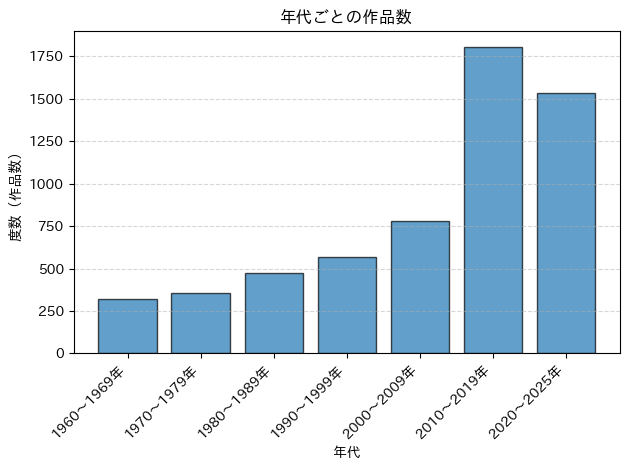

In [60]:
import matplotlib.pyplot as plt
import japanize_matplotlib

decade_list = ['1960～1969年', '1970～1979年', '1980～1989年', '1990～1999年', '2000～2009年', '2010～2019年', '2020～2025年']

# ① 年代ごとの作品数を数え、decade_list の順に並べる（該当なしは0）
counts = df_details["decade"].value_counts().reindex(decade_list, fill_value=0)

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)

# ② 棒グラフを描画
ax.bar(counts.index, counts.values, edgecolor="black", alpha=0.7)

# ③ ラベル・タイトル・補助線
ax.set_xlabel("年代")
ax.set_ylabel("度数（作品数）")
ax.set_title("年代ごとの作品数")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.xticks(rotation=45, ha="right")  # ラベルが重なる場合に斜めにする

plt.tight_layout()

plt.savefig(f'{base_path}/movie_count_per_year.png')

plt.show()

In [20]:
print(counts)

decade
1960～1969年     320
1970～1979年     358
1980～1989年     476
1990～1999年     568
2000～2009年     780
2010～2019年    1807
2020～2025年    1537
Name: count, dtype: int64


In [23]:
df_movies_details_2020_ = df_details[df_details['decade'] == '2000～2009年']
df_movies_details_2020_ ['original_title']

,original_title
1722,Gladiator
1723,Charlie's Angels
1724,American Psycho
1725,Scary Movie
1726,Cast Away
1727,Memento
1728,Snatch
1729,Final Destination
1730,Mission: Impossible II
1731,How the Grinch Stole Christmas


# レビューデータ


In [24]:
df_reviews = pd.read_csv(f'{base_path}/tmdb_movies_reviews_1960_2025.csv',encoding ='utf-8' )

In [27]:
df_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20622 entries, 0 to 20621
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   movie_id        20622 non-null  int64 
 1   year            20622 non-null  int64 
 2   author          20622 non-null  object
 3   author_details  20622 non-null  object
 4   content         20621 non-null  object
 5   created_at      20622 non-null  object
 6   id              20622 non-null  object
 7   updated_at      20622 non-null  object
 8   url             20622 non-null  object
 9   review_counts   20622 non-null  int64 
dtypes: int64(3), object(7)
memory usage: 1.6+ MB


In [25]:
print(df_reviews["author"].nunique())

2288


In [26]:
df_reviews["review_counts"] = df_reviews.groupby("author")["author"].transform("count")
df_reviews.describe()

,movie_id,year,review_counts
count,2.062200e+04,20622.000000,20622.000000
mean,3.428464e+05,2008.624139,667.496654
std,3.662871e+05,16.536296,885.067153
min,1.100000e+01,1960.000000,1.000000
25%,1.163100e+04,2000.000000,30.000000
50%,2.685310e+05,2015.000000,289.000000
75%,5.603910e+05,2021.000000,957.000000
max,1.748022e+06,2025.000000,2750.000000


In [32]:
df_reviews['author_details']

Output hidden; open in https://colab.research.google.com to view.

In [39]:
import json
import pandas as pd

def safe_json_loads(x):
    """JSON文字列を辞書に変換する。欠損値や不正な値は空の辞書にする"""
    if pd.isna(x):
        return {}
    try:
        return json.loads(x)
    except (json.JSONDecodeError, TypeError):
        return {}

# ① content が欠損している行を除き、行番号を0から振り直す
df_reviews_1 = df_reviews.dropna(subset=["content"]).reset_index(drop=True).copy()

# ② JSON文字列を辞書に変換
df_reviews_1["author_details"] = df_reviews_1["author_details"].apply(safe_json_loads)

# ③ 辞書をキーごとの列に展開
df_expanded = pd.json_normalize(df_reviews_1["author_details"])

# ④ 元のデータ（author_details 列を除く）と横に連結
df_review_expanded = pd.concat(
    [df_reviews_1.drop(columns=["author_details"]), df_expanded],
    axis=1
)

# ⑤ 不要な列を削除（存在しない列があってもエラーにしない）
df_review_expanded_new = df_review_expanded.drop(
    columns=["url", "avatar_path", "name", "username", "created_at", "updated_at"],
    errors="ignore"
)
df_review_new = df_review_expanded_new.dropna(subset=["rating"]).reset_index(drop=True).copy()

# ⑥ CSVに保存
df_review_new.to_csv(
    f"{base_path}/tmdb_movies_reviews_1960_2025.csv",
    index=False, encoding="utf-8"
)

In [42]:
df_review_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18633 entries, 0 to 18632
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   movie_id       18633 non-null  int64  
 1   year           18633 non-null  int64  
 2   author         18633 non-null  object 
 3   content        18633 non-null  object 
 4   id             18633 non-null  object 
 5   review_counts  18633 non-null  int64  
 6   rating         18633 non-null  float64
dtypes: float64(1), int64(3), object(3)
memory usage: 1019.1+ KB


In [43]:
print(df_review_new["author"].nunique())

1632


In [55]:
print(df_review_new["movie_id"].nunique())

5819


In [46]:
df_filetering = df_review_new[(df_review_new['review_counts'] >=30) & (df_review_new['review_counts'] <= 100)]
(df_filetering["author"].nunique())

32

In [57]:
df_filetering_10 = df_review_new[df_review_new['review_counts'] >=10]
print(df_filetering_10["author"].nunique())

137


In [51]:
df_review_new.describe()

,movie_id,year,review_counts,rating
count,1.863300e+04,18633.000000,18633.000000,18633.00000
mean,3.426060e+05,2008.175871,732.083776,6.57688
std,3.682764e+05,16.854664,902.958322,2.09599
min,1.100000e+01,1960.000000,1.000000,0.50000
25%,1.141500e+04,1999.000000,62.000000,6.00000
50%,2.631090e+05,2015.000000,350.000000,7.00000
75%,5.660760e+05,2021.000000,979.000000,8.00000
max,1.748022e+06,2025.000000,2750.000000,10.00000


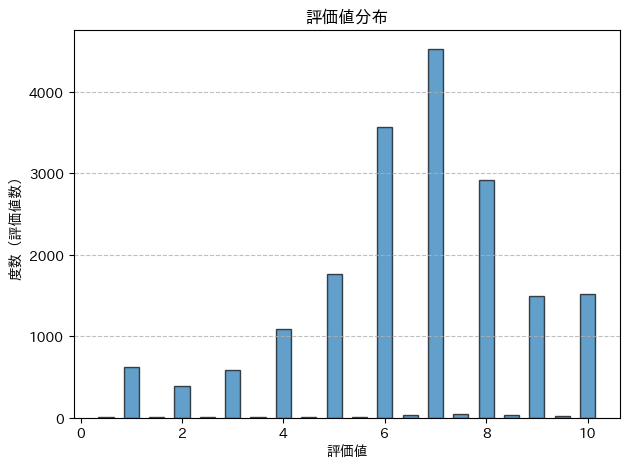

In [72]:
rating_list = [ 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7, 7.5, 8, 8.5, 9, 9.5, 10]

# ① 年代ごとの作品数を数え、decade_list の順に並べる（該当なしは0）
counts = df_review_new["rating"].value_counts().reindex(rating_list, fill_value=0)

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)

# ② 棒グラフを描画
ax.bar(counts.index, counts.values, edgecolor="black", width=0.3, alpha=0.7)

# ③ ラベル・タイトル・補助線
ax.set_xlabel("評価値")
ax.set_ylabel("度数（評価値数）")
ax.set_title("評価値分布")
ax.grid(axis="y", linestyle="--", alpha=0.8)

plt.tight_layout()

plt.savefig(f'{base_path}/rating.png')

plt.show()

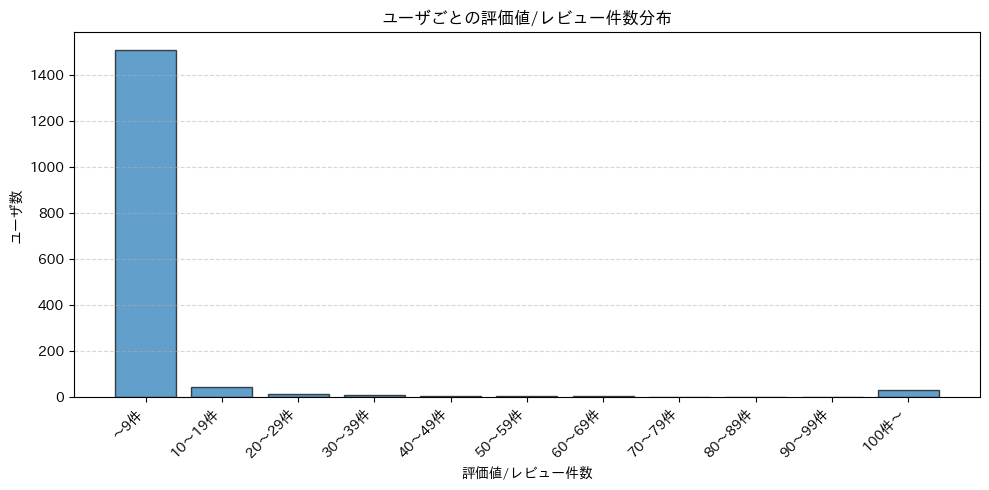

rating
～9件       1510
10～19件      43
20～29件      16
30～39件      11
40～49件       7
50～59件       5
60～69件       6
70～79件       0
80～89件       0
90～99件       0
100件～       34
Name: count, dtype: int64


In [73]:
# ① author ごとの評価値の件数（NaN の評価は数えない）
user_counts = df_review_new.groupby("author")["rating"].count()

# ② 10件刻みの区間を作成（0〜9, 10〜19, …, 90〜99, 100〜）
bins = list(range(0, 101, 10)) + [np.inf]
labels = ["～9件"] + [f"{i}～{i+9}件" for i in range(10, 100, 10)] + ["100件～"]

user_bins = pd.cut(user_counts, bins=bins, labels=labels, right=False)

# ③ 区間ごとのユーザ数を数え、区間の順に並べる
dist = user_bins.value_counts().reindex(labels, fill_value=0)

# ④ 棒グラフを描画
fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(1, 1, 1)

ax.bar(dist.index, dist.values, edgecolor="black", alpha=0.7)

ax.set_xlabel("評価値/レビュー件数")
ax.set_ylabel("ユーザ数")
ax.set_title("ユーザごとの評価値/レビュー件数分布")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.savefig(f"{base_path}/user_rating_counts.png")
plt.show()

# 確認用：区間ごとのユーザ数
print(dist)

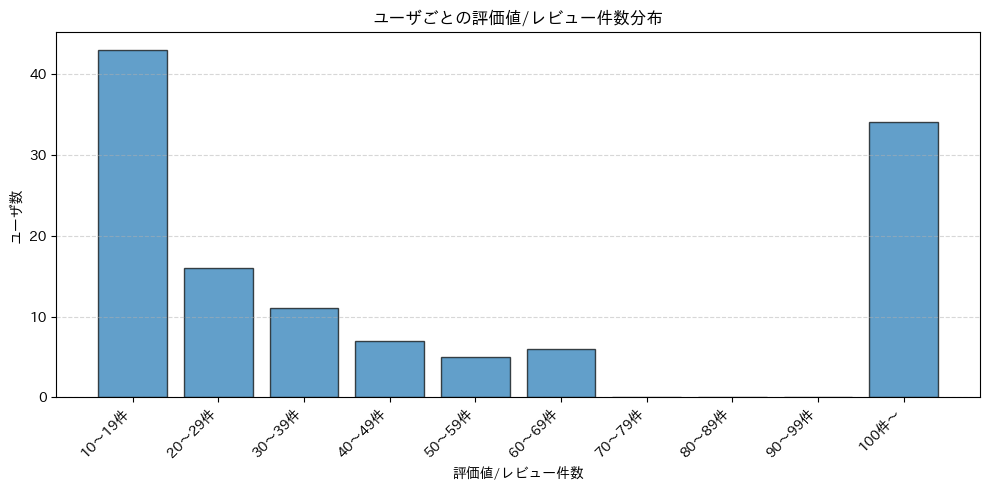

rating
10～19件    43
20～29件    16
30～39件    11
40～49件     7
50～59件     5
60～69件     6
70～79件     0
80～89件     0
90～99件     0
100件～     34
Name: count, dtype: int64


In [76]:

# ① author ごとの評価値の件数（変更なし）
user_counts = df_review_new.groupby("author")["rating"].count()

# ② 10件未満のユーザを除外し、10件刻みの区間を作成（10〜19, …, 90〜99, 100〜）
user_counts = user_counts[user_counts >= 10]

bins = list(range(10, 101, 10)) + [np.inf]
labels = [f"{i}～{i+9}件" for i in range(10, 100, 10)] + ["100件～"]

user_bins = pd.cut(user_counts, bins=bins, labels=labels, right=False)

# ③ 以降は前回と同じ
dist = user_bins.value_counts().reindex(labels, fill_value=0)

# ④ 棒グラフを描画
fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(1, 1, 1)

ax.bar(dist.index, dist.values, edgecolor="black", alpha=0.7)

ax.set_xlabel("評価値/レビュー件数")
ax.set_ylabel("ユーザ数")
ax.set_title("ユーザごとの評価値/レビュー件数分布")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.savefig(f"{base_path}/user_rating_counts_10_.png")
plt.show()

# 確認用：区間ごとのユーザ数
print(dist)

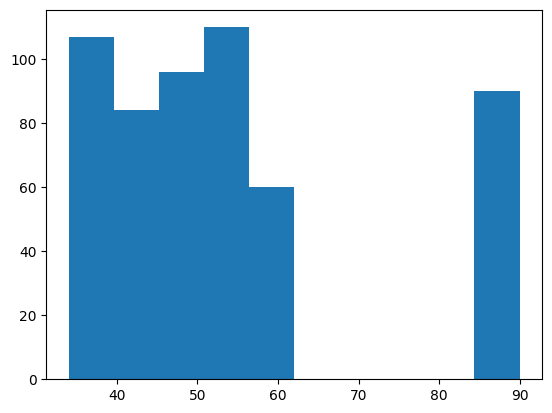

In [ ]:
df_reviews_filtering = df_reviews[(df_reviews['review_counts']<100) & (df_reviews['review_counts'] > 30)]
plt.hist(df_reviews_filtering['review_counts'])
plt.show()

In [ ]:
one = df_reviews[df_reviews['review_counts'] == 1]
print(len(one))

367
